In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display


In [3]:
project_root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "data" / "processed" / "btc_spy_daily.csv").exists()
)
PROCESSED_DIR = project_root / "data" / "processed"
RESULTS_DIR = project_root / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PERIODS_PER_YEAR = 252
ANNUAL_RISK_FREE_RATE = 0.0
ANNUAL_TARGET_RETURN = 0.0
assert ANNUAL_RISK_FREE_RATE > -1 and ANNUAL_TARGET_RETURN > -1

risk_free_per_period = (1 + ANNUAL_RISK_FREE_RATE) ** (1 / PERIODS_PER_YEAR) - 1
target_per_period = (1 + ANNUAL_TARGET_RETURN) ** (1 / PERIODS_PER_YEAR) - 1


In [4]:
prices = pd.read_csv(
    PROCESSED_DIR / "btc_spy_daily.csv", index_col="date", parse_dates=True
).rename(columns={"price_btc": "BTC", "price_spy": "SPY"})[["BTC", "SPY"]]

assert prices.index.is_monotonic_increasing, "Prices must be sorted by date."
assert prices.index.is_unique, "Duplicate dates found."
assert np.isfinite(prices.to_numpy()).all(), "Missing or infinite prices found."
assert prices.gt(0).all().all(), "Prices must be positive."
assert len(prices) >= 3, "At least three prices are required."

returns = prices.pct_change(fill_method=None).iloc[1:]
years = (prices.index[-1] - prices.index[0]).days / 365.25
assert years > 0
period_label = f"{prices.index[0]:%Y-%m-%d} to {prices.index[-1]:%Y-%m-%d}"
print(f"{period_label} | {len(returns):,} return observations | {years:.3f} years")
display(returns.head().style.format("{:.2%}"))


2013-12-27 to 2026-11-12 | 3,238 return observations | 12.876 years


,BTC,SPY
date,,
2013-12-30 00:00:00,2.87%,-0.02%
2013-12-31 00:00:00,-0.28%,0.47%
2014-01-02 00:00:00,6.42%,-0.96%
2014-01-03 00:00:00,2.04%,-0.02%
2014-01-06 00:00:00,16.44%,-0.29%


In [5]:
excess_returns = returns - risk_free_per_period
excess_std = excess_returns.std(ddof=1)
annualized_excess_mean = excess_returns.mean() * PERIODS_PER_YEAR
annualized_excess_volatility = excess_std * np.sqrt(PERIODS_PER_YEAR)

if excess_std.eq(0).any():
    raise ValueError("Sharpe is undefined for an asset with zero return volatility.")
sharpe = annualized_excess_mean / annualized_excess_volatility
sharpe.name = "Sharpe"
display(sharpe.to_frame().style.format("{:.3f}"))


,Sharpe
BTC,0.875
SPY,0.827


In [6]:
target_excess_returns = returns - target_per_period
shortfalls = target_excess_returns.clip(upper=0)
downside_deviation = shortfalls.pow(2).mean().pow(0.5)
annualized_downside_deviation = downside_deviation * np.sqrt(PERIODS_PER_YEAR)
annualized_target_excess_mean = target_excess_returns.mean() * PERIODS_PER_YEAR

if downside_deviation.eq(0).any():
    raise ValueError("Sortino is undefined when an asset has no below-target returns.")
sortino = annualized_target_excess_mean / annualized_downside_deviation
sortino.name = "Sortino"
display(sortino.to_frame().style.format("{:.3f}"))


,Sortino
BTC,1.307
SPY,1.165


In [7]:
wealth = prices.div(prices.iloc[0])
running_peak = wealth.cummax()
drawdowns = wealth / running_peak - 1
maximum_drawdown = drawdowns.min()  # Signed losses, e.g. -0.50 means -50%.
cagr = (prices.iloc[-1] / prices.iloc[0]) ** (1 / years) - 1

if maximum_drawdown.eq(0).any():
    raise ValueError("Calmar is undefined when maximum drawdown is zero.")
calmar = cagr / maximum_drawdown.abs()
calmar.name = "Calmar (full period)"
display(pd.DataFrame({"CAGR": cagr, "Maximum drawdown": maximum_drawdown}).style.format("{:.2%}"))
display(calmar.to_frame().style.format("{:.3f}"))


,CAGR,Maximum drawdown
BTC,43.01%,-82.90%
SPY,13.50%,-33.72%


,Calmar (full period)
BTC,0.519
SPY,0.401


In [8]:
ratio_summary = pd.concat([sharpe, sortino, calmar], axis=1)
ratio_summary.index.name = "Asset"
components = pd.DataFrame({
    "Annualized mean excess return (risk-free)": annualized_excess_mean,
    "Annualized excess-return volatility": annualized_excess_volatility,
    "Annualized mean excess return (target)": annualized_target_excess_mean,
    "Annualized downside deviation": annualized_downside_deviation,
    "CAGR": cagr,
    "Maximum drawdown": maximum_drawdown,
})
components.index.name = "Asset"
display(ratio_summary.style.format("{:.3f}").set_caption(period_label))
display(components.style.format("{:.2%}"))


,Sharpe,Sortino,Calmar (full period)
Asset,,,
BTC,0.875,1.307,0.519
SPY,0.827,1.165,0.401


,Annualized mean excess return (risk-free),Annualized excess-return volatility,Annualized mean excess return (target),Annualized downside deviation,CAGR,Maximum drawdown
Asset,,,,,,
BTC,57.97%,66.25%,57.97%,44.37%,43.01%,-82.90%
SPY,14.17%,17.13%,14.17%,12.16%,13.50%,-33.72%


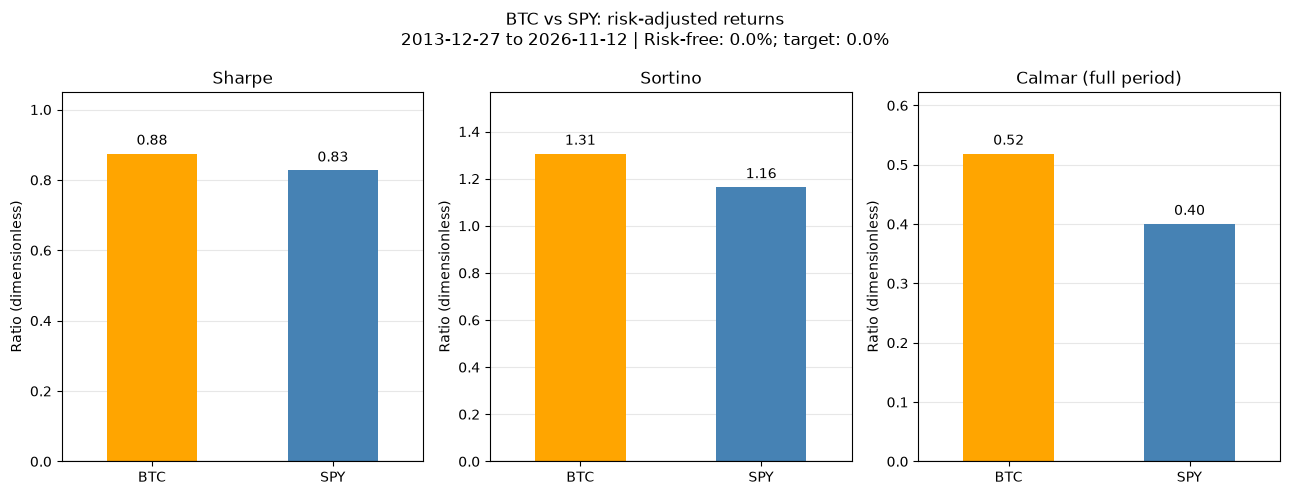

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5))
for ax, metric in zip(axes, ratio_summary.columns):
    values = ratio_summary[metric]
    values.plot.bar(ax=ax, color=["orange", "steelblue"], rot=0)
    ax.set_title(metric)
    ax.set_xlabel("")
    ax.set_ylabel("Ratio (dimensionless)")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.bar_label(ax.containers[0], labels=[f"{v:.2f}" for v in values], padding=4)
    ax.margins(y=0.2)
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
fig.suptitle(f"BTC vs SPY: risk-adjusted returns\n{period_label} | Risk-free: {ANNUAL_RISK_FREE_RATE:.1%}; target: {ANNUAL_TARGET_RETURN:.1%}")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "risk_adjusted_ratios.png", dpi=300)
plt.show()


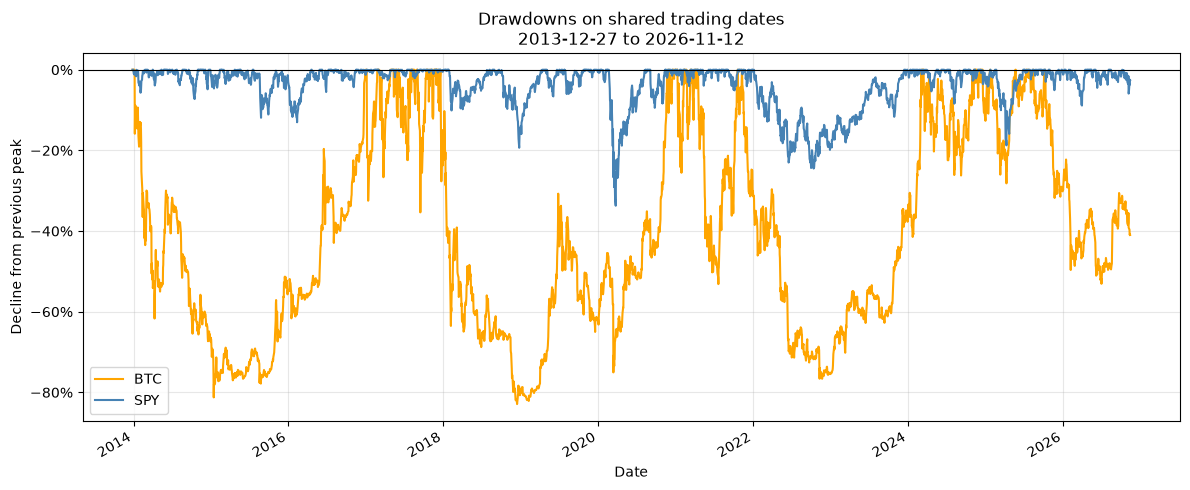

In [10]:
ax = drawdowns.plot(figsize=(12, 5), color=["orange", "steelblue"])
ax.set_title(f"Drawdowns on shared trading dates\n{period_label}")
ax.set_xlabel("Date")
ax.set_ylabel("Decline from previous peak")
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.axhline(0, color="black", linewidth=0.8)
ax.grid(alpha=0.3)
fig = ax.get_figure()
fig.tight_layout()
fig.savefig(RESULTS_DIR / "risk_adjusted_drawdowns.png", dpi=300)
plt.show()


In [11]:
import json

ratio_summary.to_csv(RESULTS_DIR / "risk_adjusted_summary.csv")
components.to_csv(RESULTS_DIR / "risk_adjusted_components.csv")
drawdowns.to_csv(RESULTS_DIR / "risk_adjusted_drawdowns.csv", index_label="date")
assumptions = {
    "price_start": str(prices.index[0].date()),
    "price_end": str(prices.index[-1].date()),
    "return_observations": len(returns),
    "elapsed_years": years,
    "periods_per_year": PERIODS_PER_YEAR,
    "annual_risk_free_rate": ANNUAL_RISK_FREE_RATE,
    "annual_target_return": ANNUAL_TARGET_RETURN,
    "return_type": "simple returns on shared trading dates",
    "sharpe_std_ddof": 1,
    "sortino_convention": "target excess mean / RMS shortfall across all observations",
    "calmar_window": "full sample; CAGR / absolute maximum observed drawdown",
}
(RESULTS_DIR / "risk_adjusted_assumptions.json").write_text(json.dumps(assumptions, indent=2), encoding="utf-8")
report = (
    '<!doctype html><html><head><meta charset="utf-8"><title>Risk-adjusted returns</title>'
    '<style>body{font-family:system-ui;max-width:1100px;margin:40px auto;padding:0 20px;}'
    'table{border-collapse:collapse;}td,th{padding:9px;border-bottom:1px solid #ddd;text-align:right;}'
    'img{max-width:100%;}</style></head><body><h1>BTC vs SPY: risk-adjusted returns</h1>'
    f'<p>{period_label} | {len(returns):,} shared-date return observations</p>'
    f'<p>Constant annual risk-free rate: {ANNUAL_RISK_FREE_RATE:.2%}; '
    f'annual Sortino target: {ANNUAL_TARGET_RETURN:.2%}. Zero defaults are educational baselines, not historical cash yields.</p>'
    + ratio_summary.style.format("{:.3f}").to_html()
    + '<h2>Components</h2>' + components.style.format("{:.2%}").to_html()
    + f'<p>Annualization: {PERIODS_PER_YEAR} observations per year. Sharpe uses sample standard deviation; '
    'Sortino uses root-mean-square shortfalls across all observations and a target-excess numerator. '
    'Calmar uses full-period CAGR divided by absolute maximum drawdown, not a trailing 36-month window.</p>'
    '<p>Shared-date closes can miss intraday and weekend drawdowns. Source timestamps may differ. '
    'Annualized arithmetic means are not CAGR. Historical ratios depend on the sample and are not forecasts.</p>'
    '<img src="risk_adjusted_ratios.png" alt="Risk-adjusted ratio comparisons">'
    '<img src="risk_adjusted_drawdowns.png" alt="Shared-date drawdown histories">'
    '</body></html>'
)
(RESULTS_DIR / "risk_adjusted_report.html").write_text(report, encoding="utf-8")
print(f"Saved three CSVs, assumptions JSON, two charts, and an HTML report to {RESULTS_DIR}")


Saved three CSVs, assumptions JSON, two charts, and an HTML report to /Users/nikolaskefalonitis/Desktop/All_folders/projects/quant/btcVSsp500/results
